# Analisis Data Transaksi & Member — UMKM Tujuan Semata

> ⚠️ **Catatan Data Dummy:** Dataset `raw_transaksi_dan_member_tujuan_semata.csv` adalah **data dummy buatan tim**, bukan data operasional nyata UMKM (riwayat transaksi asli belum tersedia). Data ini dibuat menyerupai kondisi kedai untuk keperluan eksplorasi, perancangan dasbor, dan demonstrasi solusi, sehingga seluruh angka di notebook ini bersifat **ilustratif**.

## 1. Business Understanding

### 1.1 Latar Belakang Masalah
**Tujuan Semata** adalah kedai makanan dan minuman di Depok yang dikelola langsung oleh pemilik (Ibu Shinta) tanpa karyawan. Berdasarkan hasil wawancara tim, terdapat tiga kendala operasional utama yang relevan dengan data transaksi:
1. **Pencatatan manual rawan salah:** Saat kedai ramai, pencatatan di kertas/kasir sering memicu *salah dengar menu* atau *double order* sehingga bahan dan waktu terbuang.
2. **Belum ada program loyalitas terstruktur:** Pemilik belum memiliki sistem membership untuk memantau pelanggan setia dan memberi poin/apresiasi.
3. **Sulit memantau performa usaha:** Pemilik belum punya ringkasan menu terlaris dan jam paling ramai sebagai dasar persiapan operasional.

### 1.2 Pertanyaan Bisnis
Untuk menjawab kebutuhan solusi web *membership* dan dasbor pemilik, analisis ini difokuskan pada **3 pertanyaan bisnis**:
1. **Operasional & Pencatatan:** Seberapa besar perbedaan tingkat kesalahan pesanan (*salah dengar* & *double order*) antara pencatatan manual dan digital, terutama saat jam ramai?
2. **Loyalitas Member:** Bagaimana kontribusi member dibanding non-member, dan apakah level member berhubungan dengan frekuensi kunjungan serta nilai belanja?
3. **Performa Menu & Waktu Ramai:** Menu apa yang paling laris/menguntungkan, dan pada jam berapa kedai paling ramai?

## 2. Data Understanding

### 2.1 Gathering Data
Pertama, kita siapkan library yang dibutuhkan dan muat dataset mentah. Data dimuat dengan `dtype=str` agar pandas tidak mengubah format asli secara otomatis (seperti angka `0` vs `Rp 0`, atau variasi format tanggal), sehingga kita bisa melihat kondisi data apa adanya.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Pengaturan tampilan tabel dan grafik agar mudah dibaca
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

In [ ]:
# Lokasi file
PATH_RAW = "data/raw/raw_transaksi_dan_member_tujuan_semata.csv"

# Baca semua kolom sebagai teks (str) terlebih dahulu untuk keperluan assessing
df_raw = pd.read_csv(PATH_RAW, dtype=str)
df_raw.head()

,No_Nota_Transaksi,Tgl_Order,Waktu_Order,Situasi_Kedai,ID_Member_Pelanggan,Level_Member,Kategori_Pelanggan,Kunjungan_Bulan_Ini,Saldo_Poin,Sumber_Order,Cara_Catat_Kasir,Kode_Menu_Pesanan,Nama_Menu_Terjual,Qty_Cup_Porsi,Harga_Satuan,Potongan_Diskon_Member,Total_Bayar_Kasir,Catatan_Kesesuaian_Order,Durasi_Penyajian_Menit
0,TS-2026-0001,2026-10-02,21:08,Normal,NON-MBR,non member,MAHASISWA,2,0,Chatbot WhatsApp/Web,Otomatis Digital (Web/Chatbot),MN095,Soto Betawi Creamy Susu + Nasi,1,28000,0,Rp 28.000,Sesuai Pesanan,8
1,TS-2026-0001,2026-10-02,21:08,Normal,NON-MBR,non member,MAHASISWA,2,0,Chatbot WhatsApp/Web,Otomatis Digital (Web/Chatbot),MN095,Soto Betawi Creamy Susu + Nasi,1,28000,0,Rp 28.000,Sesuai Pesanan,8
2,TS-2026-0002,26/07/2026,13:21,Ramai (Peak Hour),MBR-1350,Bronze Member,Ibu-ibu,2,34,Website Membership & Order,Otomatis Digital (Web/Chatbot),MN057,Strawberry Milkshake Ceria,1,Rp 16000,0,Rp 16.000,Sesuai Pesanan,11
3,TS-2026-0003,17/06/2026,12:00,Ramai (Peak Hour),NON-MBR,Non-Member,Pekerja Menengah,3,0,Website Membership & Order,Otomatis Digital (Web/Chatbot),MN097,Tahu Cabai Garam Crispy,1,Rp 15000,0,15000,Sesuai Pesanan,5
4,TS-2026-0004,10/05/2026,16:17,Normal,MBR-1022,GOLD VIP,Anak SD/SMP,16,400,Chatbot WhatsApp/Web,Otomatis Digital (Web/Chatbot),MN049,Banana Milk Korean Style,2,18000,3600,Rp32400,Sesuai Pesanan,6


### 2.2 Assessing Data
Sekarang kita periksa kualitas data secara bertahap: ukuran data, tipe kolom, nilai kosong (*missing value*), duplikat, konsistensi penulisan, hingga nilai yang tidak masuk akal.

In [3]:
# Cek dimensi dataset (jumlah baris dan kolom)
print(f"Jumlah baris : {df_raw.shape[0]}")
print(f"Jumlah kolom : {df_raw.shape[1]}")

Jumlah baris : 2620
Jumlah kolom : 19


In [4]:
# Cek ringkasan kolom dan jumlah nilai non-null
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2620 entries, 0 to 2619
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   No_Nota_Transaksi         2620 non-null   str  
 1   Tgl_Order                 2620 non-null   str  
 2   Waktu_Order               2620 non-null   str  
 3   Situasi_Kedai             2475 non-null   str  
 4   ID_Member_Pelanggan       2314 non-null   str  
 5   Level_Member              2492 non-null   str  
 6   Kategori_Pelanggan        2620 non-null   str  
 7   Kunjungan_Bulan_Ini       2438 non-null   str  
 8   Saldo_Poin                2504 non-null   str  
 9   Sumber_Order              2620 non-null   str  
 10  Cara_Catat_Kasir          2620 non-null   str  
 11  Kode_Menu_Pesanan         2620 non-null   str  
 12  Nama_Menu_Terjual         2620 non-null   str  
 13  Qty_Cup_Porsi             2620 non-null   str  
 14  Harga_Satuan              2620 non-null   str  
 15

In [5]:
# Hitung jumlah nilai kosong (missing value) per kolom
df_raw.isna().sum()

No_Nota_Transaksi             0
Tgl_Order                     0
Waktu_Order                   0
Situasi_Kedai               145
ID_Member_Pelanggan         306
Level_Member                128
Kategori_Pelanggan            0
Kunjungan_Bulan_Ini         182
Saldo_Poin                  116
Sumber_Order                  0
Cara_Catat_Kasir              0
Kode_Menu_Pesanan             0
Nama_Menu_Terjual             0
Qty_Cup_Porsi                 0
Harga_Satuan                  0
Potongan_Diskon_Member        0
Total_Bayar_Kasir             0
Catatan_Kesesuaian_Order      0
Durasi_Penyajian_Menit      128
dtype: int64

In [6]:
# Cek apakah ada baris yang terduplikasi penuh atau nomor nota yang ganda
print("Duplikat baris penuh :", df_raw.duplicated().sum())
print("Duplikat No_Nota     :", df_raw["No_Nota_Transaksi"].duplicated().sum())
print("No_Nota unik         :", df_raw["No_Nota_Transaksi"].nunique())

Duplikat baris penuh : 120
Duplikat No_Nota     : 120
No_Nota unik         : 2500


In [7]:
# Lihat contoh baris yang terduplikasi
df_raw[df_raw.duplicated(keep=False)].head()

,No_Nota_Transaksi,Tgl_Order,Waktu_Order,Situasi_Kedai,ID_Member_Pelanggan,Level_Member,Kategori_Pelanggan,Kunjungan_Bulan_Ini,Saldo_Poin,Sumber_Order,Cara_Catat_Kasir,Kode_Menu_Pesanan,Nama_Menu_Terjual,Qty_Cup_Porsi,Harga_Satuan,Potongan_Diskon_Member,Total_Bayar_Kasir,Catatan_Kesesuaian_Order,Durasi_Penyajian_Menit
0,TS-2026-0001,2026-10-02,21:08,Normal,NON-MBR,non member,MAHASISWA,2,0,Chatbot WhatsApp/Web,Otomatis Digital (Web/Chatbot),MN095,Soto Betawi Creamy Susu + Nasi,1,28000,0,Rp 28.000,Sesuai Pesanan,8
1,TS-2026-0001,2026-10-02,21:08,Normal,NON-MBR,non member,MAHASISWA,2,0,Chatbot WhatsApp/Web,Otomatis Digital (Web/Chatbot),MN095,Soto Betawi Creamy Susu + Nasi,1,28000,0,Rp 28.000,Sesuai Pesanan,8
22,TS-2026-0022,26/07/2026,17:15,Normal,MBR-1034,silver,Mahasiswa,4,131,Datang Langsung (Walk-in),Otomatis Digital (Web/Chatbot),MN021,Es Kopi Susu Tujuan (Gula Aren),2,18000,1800,34200,Sesuai Pesanan,11
23,TS-2026-0022,26/07/2026,17:15,Normal,MBR-1034,silver,Mahasiswa,4,131,Datang Langsung (Walk-in),Otomatis Digital (Web/Chatbot),MN021,Es Kopi Susu Tujuan (Gula Aren),2,18000,1800,34200,Sesuai Pesanan,11
44,TS-2026-0043,17/08/2026,18.44,Ramai (Peak Hour),MBR-1398,bronze,Mahasiswa,2,71,Datang Langsung (Walk-in),Catat Kertas Manual,MN078,Rice Bowl Beef Blackpepper,3,Rp 28000,0,Rp84000,Double Order (Pesanan Ganda),180


Dari pengecekan awal di atas, sudah terlihat **120 baris duplikat penuh** dan **6 kolom yang memiliki missing value** (`ID_Member_Pelanggan`, `Kunjungan_Bulan_Ini`, `Situasi_Kedai`, `Level_Member`, `Durasi_Penyajian_Menit`, `Saldo_Poin`).

Selanjutnya memeriksa konsistensi format penulisan pada tanggal, waktu, harga/total, kode menu, dan label kategori.

In [8]:
# Lihat contoh variasi format penulisan tanggal dan waktu
print("Contoh format Tgl_Order   :", df_raw["Tgl_Order"].head(8).tolist())
print("Contoh format Waktu_Order :", df_raw["Waktu_Order"].unique()[:10])

Contoh format Tgl_Order   : ['2026-10-02', '2026-10-02', '26/07/2026', '17/06/2026', '10/05/2026', '10-07-2026', '26-08-2026', '22-07-2026']
Contoh format Waktu_Order : <StringArray>
['21:08', '13:21', '12:00', '16:17', '11:41', '16:18', '16.28', '16.02', '16.01', '17.20']
Length: 10, dtype: str


In [9]:
# Lihat contoh variasi penulisan kolom harga, diskon, dan total bayar
df_raw[["Harga_Satuan", "Potongan_Diskon_Member", "Total_Bayar_Kasir"]].head(8)

,Harga_Satuan,Potongan_Diskon_Member,Total_Bayar_Kasir
0,28000,0,Rp 28.000
1,28000,0,Rp 28.000
2,Rp 16000,0,Rp 16.000
3,Rp 15000,0,15000
4,18000,3600,Rp32400
5,Rp 22000,0,22000
6,Rp 30000,0,Rp30000
7,Rp 19000,0,19000


In [10]:
# Cek apakah penulisan kode menu konsisten (mis. huruf besar vs huruf kecil)
kode_asli = df_raw["Kode_Menu_Pesanan"].nunique()
kode_rapi = df_raw["Kode_Menu_Pesanan"].str.upper().str.strip().nunique()
print(f"Kode menu unik (mentah)     : {kode_asli}")
print(f"Kode menu unik (dirapikan)  : {kode_rapi}")

Kode menu unik (mentah)     : 232
Kode menu unik (dirapikan)  : 120


In [11]:
# Cek variasi label pada kolom Level_Member
df_raw["Level_Member"].value_counts(dropna=False)

Level_Member
Bronze Member    239
BRONZE           235
Bronze           224
bronze           221
Silver Member    163
Non-Member       161
Silver           153
SILVER           148
silver           146
Guest            131
NaN              128
-                126
Belum Member     126
non member       120
GOLD VIP          89
Gold              75
gold              70
Gold Member       65
Name: count, dtype: int64

In [12]:
# Cek variasi label pada kolom Kategori_Pelanggan
df_raw["Kategori_Pelanggan"].value_counts(dropna=False)

Kategori_Pelanggan
Mahasiswi           248
Mahasiswa           234
mhs                 233
Mahasiswa           231
Kuliah              223
MAHASISWA           213
Umum/Pekerja        132
Karyawan            119
pekerja menengah    108
Pekerja             105
Pekerja Menengah    101
Ibu Rumah Tangga     83
emak2                78
Ibu-ibu              76
ibu2                 75
Anak-anak            68
Ibu-Ibu              65
bocil                62
Anak SD/SMP          59
Pelajar SD/SMP       59
anak sd              48
Name: count, dtype: int64

In [13]:
# Cek variasi nilai pada kolom Sumber_Order, Cara_Catat_Kasir, dan Catatan_Kesesuaian_Order
for kolom in ["Sumber_Order", "Cara_Catat_Kasir", "Catatan_Kesesuaian_Order"]:
    print(f"--- {kolom} ---")
    print(df_raw[kolom].value_counts(dropna=False), "\n")

--- Sumber_Order ---
Sumber_Order
Website Membership & Order    934
Chatbot WhatsApp/Web          831
Datang Langsung (Walk-in)     597
Link Bio Instagram/TikTok     258
Name: count, dtype: int64 

--- Cara_Catat_Kasir ---
Cara_Catat_Kasir
Otomatis Digital (Web/Chatbot)    2144
Manual Kertas & Kasir Pintar       287
Catat Kertas Manual                189
Name: count, dtype: int64 

--- Catatan_Kesesuaian_Order ---
Catatan_Kesesuaian_Order
Sesuai Pesanan                      2459
Salah Dengar Menu (Dibuat Ulang)     121
Double Order (Pesanan Ganda)          40
Name: count, dtype: int64 



Terlihat banyak variasi penulisan pada `Level_Member` (18 label untuk 4 status) dan `Kategori_Pelanggan` (21 label seperti `mhs`, `emak2`, `bocil`).

Sekarang kita periksa apakah ada **nilai yang tidak wajar** pada kolom jumlah porsi (`Qty_Cup_Porsi`) dan lama penyajian (`Durasi_Penyajian_Menit`).

In [14]:
# Cek sebaran nilai Qty_Cup_Porsi
df_raw["Qty_Cup_Porsi"].value_counts().sort_index()

Qty_Cup_Porsi
-1       3
1     1392
2      717
3      306
4      136
5       66
Name: count, dtype: int64

In [15]:
# Konversi sementara Durasi_Penyajian_Menit ke angka untuk melihat statistik dan nilai ekstrem
durasi_cek = pd.to_numeric(df_raw["Durasi_Penyajian_Menit"])
durasi_cek.describe()

count    2492.000000
mean        9.429374
std        28.845027
min         4.000000
25%         6.000000
50%         8.000000
75%        10.000000
max       999.000000
Name: Durasi_Penyajian_Menit, dtype: float64

In [16]:
# Tampilkan baris dengan durasi penyajian di atas 60 menit (terindikasi salah input)
df_raw[durasi_cek > 60][["No_Nota_Transaksi", "Nama_Menu_Terjual", "Qty_Cup_Porsi", "Durasi_Penyajian_Menit"]]

,No_Nota_Transaksi,Nama_Menu_Terjual,Qty_Cup_Porsi,Durasi_Penyajian_Menit
44,TS-2026-0043,Rice Bowl Beef Blackpepper,3,180
45,TS-2026-0043,Rice Bowl Beef Blackpepper,3,180
209,TS-2026-0200,Spaghetti Aglio Olio Tuna Pedas,3,999
537,TS-2026-0513,Nasi Goreng Kampung Cabe Ijo,2,999
1073,TS-2026-1025,Croffle Choco Almond (Isi 2),2,120


Ditemukan **3 transaksi dengan `Qty_Cup_Porsi` bernilai `-1`** dan **5 transaksi dengan durasi 120–999 menit** (tidak wajar untuk penyajian kedai yang mediannya 8 menit).

Sebelum membersihkan data, kita juga cek **hubungan antar-kolom** untuk melihat apakah ada nilai kosong yang bisa diisi secara akurat dan apakah perhitungan total bayar sudah sesuai.

In [17]:
# Cek hubungan antara jam order dengan Situasi_Kedai (Normal vs Ramai)
jam_cek = df_raw["Waktu_Order"].str[:2].astype(int)
pd.crosstab(jam_cek, df_raw["Situasi_Kedai"].fillna("(kosong)"))

Situasi_Kedai,(kosong),Normal,Ramai (Peak Hour)
Waktu_Order,,,
10,6,51,0
11,8,113,0
12,11,0,307
13,24,0,320
14,5,143,0
15,7,101,0
16,6,169,0
17,8,172,0
18,16,0,287


In [18]:
# Cek hubungan antara ID_Member_Pelanggan dengan Level_Member
id_kosong_atau_non = df_raw["ID_Member_Pelanggan"].fillna("(kosong)").replace(r"^MBR-.*", "MBR-xxxx", regex=True)
pd.crosstab(df_raw["Level_Member"].fillna("(kosong)"), id_kosong_atau_non)

ID_Member_Pelanggan,(kosong),MBR-xxxx,NON-MBR
Level_Member,,,
(kosong),50,0,78
-,43,0,83
BRONZE,0,235,0
Belum Member,51,0,75
Bronze,0,224,0
Bronze Member,0,239,0
GOLD VIP,0,89,0
Gold,0,75,0
Gold Member,0,65,0


In [19]:
# Fungsi bantu sederhana untuk mengubah teks rupiah menjadi angka integer
def bersihkan_angka(series):
    """Hapus karakter selain angka dan tanda minus, lalu konversi ke Int64 (mendukung NA)."""
    teks_angka = series.str.replace(r"[^0-9-]", "", regex=True)
    return pd.to_numeric(teks_angka).astype("Int64")

In [20]:
# Cek apakah Total_Bayar_Kasir selalu sama dengan (Qty * Harga_Satuan) - Potongan_Diskon_Member
qty_cek = bersihkan_angka(df_raw["Qty_Cup_Porsi"])
harga_cek = bersihkan_angka(df_raw["Harga_Satuan"])
diskon_cek = bersihkan_angka(df_raw["Potongan_Diskon_Member"])
total_cek = bersihkan_angka(df_raw["Total_Bayar_Kasir"])

selisih_total = (qty_cek * harga_cek - diskon_cek) != total_cek
print("Jumlah baris dengan total bayar tidak cocok:", selisih_total.sum())

Jumlah baris dengan total bayar tidak cocok: 63


In [21]:
# Tampilkan contoh baris yang total bayarnya tidak cocok untuk memahami penyebabnya
kolom_cek = ["Level_Member", "Qty_Cup_Porsi", "Harga_Satuan", "Potongan_Diskon_Member", "Total_Bayar_Kasir"]
df_raw.loc[selisih_total, kolom_cek].head(10)

,Level_Member,Qty_Cup_Porsi,Harga_Satuan,Potongan_Diskon_Member,Total_Bayar_Kasir
29,silver,1,25000,Rp 0,23750
81,Bronze Member,-1,22000,0,66000
203,gold,4,24000,Rp 0,86400
204,SILVER,1,15000,Rp 0,14250
289,gold,2,18000,Rp 0,Rp 32.400
367,BRONZE,-1,23000,0,92000
416,GOLD VIP,1,28000,Rp 0,25200
458,Silver,1,23000,Rp 0,21850
459,Silver Member,2,Rp 16000,Rp 0,Rp 30.400
465,Gold Member,3,Rp 22000,Rp 0,59400


Dari hasil pengecekan di atas, kita menemukan pola yang jelas untuk tahap *Cleaning*:
- **Duplikat:** Ada 120 baris duplikat penuh → akan dihapus.
- **Format Tanggal & Waktu:** Tanggal memakai 3 format berbeda (`YYYY-MM-DD`, `DD/MM/YYYY`, `DD-MM-YYYY`) dan waktu memakai `:` serta `.` → akan diseragamkan.
- **Tipe Numerik:** Harga, diskon, total, qty, durasi, kunjungan, dan poin masih berupa teks bercampur `Rp`/titik → akan dikonversi ke angka.
- **Label Tidak Konsisten:** `Kode_Menu_Pesanan` (232 variasi → 120 kode), `Level_Member` (18 label → 4 level), dan `Kategori_Pelanggan` (21 label → 4 segmen) akan distandardisasi.
- **Missing Value Terpola:**
  - `Situasi_Kedai` selalu *Ramai (Peak Hour)* di jam 12–13 dan 18–20, dan *Normal* di jam lain → nilai kosong bisa diimputasi dari jam.
  - `ID_Member_Pelanggan` yang kosong seluruhnya adalah non-member (`Non-Member`, `Guest`, `Belum Member`, `-`, atau kosong) → diisi `NON-MBR`.
  - `Saldo_Poin` kosong pada non-member diisi `0`, sedangkan poin & kunjungan member yang kosong dibiarkan kosong agar tidak mengarang data.
- **Anomali Nilai:**
  - `Qty_Cup_Porsi = -1` (3 baris) ternyata total bayarnya positif → bisa dipulihkan dari `(Total + Diskon) / Harga`.
  - Pada sebagian transaksi *Silver/Gold*, `Potongan_Diskon_Member` tercatat `0` padahal `Total_Bayar_Kasir` sudah terpotong 5% atau 10% → diskon dihitung ulang dari selisihnya.
  - `Durasi_Penyajian_Menit > 60` (5 baris: 120–999 menit) diubah menjadi kosong (`NA`) agar tidak merusak rata-rata.

## 3. Data Preparation (Cleaning)
Setiap langkah pembersihan dilakukan pada salinan dataframe (`df`) agar data mentah (`df_raw`) tetap utuh sebagai pembanding.

### 3.1 Hapus baris duplikat

In [22]:
# Salin data mentah dan hapus baris yang 100% identik
df = df_raw.drop_duplicates().reset_index(drop=True)

print(f"Baris sebelum : {len(df_raw)}")
print(f"Baris sesudah : {len(df)}")
print(f"No_Nota unik  : {df['No_Nota_Transaksi'].is_unique}")

Baris sebelum : 2620
Baris sesudah : 2500
No_Nota unik  : True


### 3.2 Rapikan format tanggal dan waktu

In [23]:
def parse_tanggal_campur(series):
    """Parse tanggal dari 3 format berbeda secara eksplisit agar hari dan bulan tidak tertukar."""
    hasil = pd.to_datetime(series, format="%Y-%m-%d", errors="coerce")
    hasil = hasil.fillna(pd.to_datetime(series, format="%d/%m/%Y", errors="coerce"))
    hasil = hasil.fillna(pd.to_datetime(series, format="%d-%m-%Y", errors="coerce"))
    return hasil

In [24]:
# Terapkan parsing tanggal dan seragamkan pemisah waktu dari '.' menjadi ':'
df["Tgl_Order"] = parse_tanggal_campur(df["Tgl_Order"])
df["Waktu_Order"] = df["Waktu_Order"].str.replace(".", ":", regex=False)

# Gabungkan tanggal dan waktu menjadi satu kolom datetime
df["Waktu_Transaksi"] = pd.to_datetime(df["Tgl_Order"].dt.strftime("%Y-%m-%d") + " " + df["Waktu_Order"])

print("Tanggal gagal parse :", df["Tgl_Order"].isna().sum())
print("Rentang tanggal     :", df["Tgl_Order"].min().date(), "s.d.", df["Tgl_Order"].max().date())

Tanggal gagal parse : 0
Rentang tanggal     : 2026-05-01 s.d. 2026-10-23


### 3.3 Konversi kolom angka & rupiah ke integer

In [25]:
# Daftar kolom yang seharusnya bertipe bilangan bulat
kolom_numerik = [
    "Qty_Cup_Porsi", "Harga_Satuan", "Potongan_Diskon_Member",
    "Total_Bayar_Kasir", "Kunjungan_Bulan_Ini", "Saldo_Poin", "Durasi_Penyajian_Menit"
]

# Bersihkan simbol 'Rp', spasi, serta titik ribuan lalu konversi ke Int64
for kol in kolom_numerik:
    df[kol] = bersihkan_angka(df[kol])

df[kolom_numerik].dtypes

Qty_Cup_Porsi             Int64
Harga_Satuan              Int64
Potongan_Diskon_Member    Int64
Total_Bayar_Kasir         Int64
Kunjungan_Bulan_Ini       Int64
Saldo_Poin                Int64
Durasi_Penyajian_Menit    Int64
dtype: object

### 3.4 Rapikan kode dan nama menu

In [26]:
# Ubah kode menu menjadi huruf kapital dan hapus spasi berlebih di awal/akhir teks
df["Kode_Menu_Pesanan"] = df["Kode_Menu_Pesanan"].str.upper().str.strip()
df["Nama_Menu_Terjual"] = df["Nama_Menu_Terjual"].str.strip()

print("Kode menu unik setelah dirapikan:", df["Kode_Menu_Pesanan"].nunique())
print("Nama menu unik setelah dirapikan:", df["Nama_Menu_Terjual"].nunique())

Kode menu unik setelah dirapikan: 120
Nama menu unik setelah dirapikan: 120


### 3.5 Standardisasi `Level_Member` dan `ID_Member_Pelanggan`

In [27]:
def rapikan_level_member(series):
    """Kelompokkan variasi label level member menjadi: Bronze, Silver, Gold, atau Non-Member."""
    teks = series.fillna("").str.lower()
    hasil = pd.Series("Non-Member", index=series.index)
    hasil[teks.str.contains("bronze")] = "Bronze"
    hasil[teks.str.contains("silver")] = "Silver"
    hasil[teks.str.contains("gold")] = "Gold"
    return hasil

In [28]:
# Terapkan standardisasi level member dan isi ID member yang kosong dengan 'NON-MBR'
df["Level_Member"] = rapikan_level_member(df["Level_Member"])
df["ID_Member_Pelanggan"] = df["ID_Member_Pelanggan"].fillna("NON-MBR")

# Buat kolom penanda boolean apakah transaksi berasal dari member
df["Is_Member"] = df["ID_Member_Pelanggan"].str.startswith("MBR")

pd.crosstab(df["Level_Member"], df["Is_Member"])

Is_Member,False,True
Level_Member,,
Bronze,0,875
Gold,0,286
Non-Member,754,0
Silver,0,585


### 3.6 Standardisasi `Kategori_Pelanggan` menjadi 4 segmen

In [29]:
# Peta pengelompokan variasi penulisan segmen pelanggan ke 4 kategori utama
peta_segmen = {
    "mahasiswa": "Mahasiswa", "mahasiswi": "Mahasiswa", "mhs": "Mahasiswa", "kuliah": "Mahasiswa",
    "umum/pekerja": "Pekerja", "karyawan": "Pekerja", "pekerja": "Pekerja", "pekerja menengah": "Pekerja",
    "ibu rumah tangga": "Ibu Rumah Tangga", "ibu2": "Ibu Rumah Tangga", "emak2": "Ibu Rumah Tangga", "ibu-ibu": "Ibu Rumah Tangga",
    "anak-anak": "Anak/Pelajar", "bocil": "Anak/Pelajar", "anak sd/smp": "Anak/Pelajar",
    "pelajar sd/smp": "Anak/Pelajar", "anak sd": "Anak/Pelajar",
}

df["Kategori_Pelanggan"] = df["Kategori_Pelanggan"].str.strip().str.lower().map(peta_segmen)

print("Segmen tidak terpetakan:", df["Kategori_Pelanggan"].isna().sum())
df["Kategori_Pelanggan"].value_counts()

Segmen tidak terpetakan: 0


Kategori_Pelanggan
Mahasiswa           1319
Pekerja              534
Ibu Rumah Tangga     362
Anak/Pelajar         285
Name: count, dtype: int64

### 3.7 Imputasi `Situasi_Kedai` berdasarkan jam

In [30]:
# Berdasarkan hasil assessing: jam 12-13 dan 18-20 selalu berstatus 'Ramai (Peak Hour)'
jam_ramai = [12, 13, 18, 19, 20]
is_jam_ramai = df["Waktu_Transaksi"].dt.hour.isin(jam_ramai)

# Isi nilai yang kosong saja sesuai aturan jam tersebut
situasi_imputasi = pd.Series("Normal", index=df.index)
situasi_imputasi[is_jam_ramai] = "Ramai (Peak Hour)"
df["Situasi_Kedai"] = df["Situasi_Kedai"].fillna(situasi_imputasi)

df["Situasi_Kedai"].value_counts(dropna=False)

Situasi_Kedai
Ramai (Peak Hour)    1524
Normal                976
Name: count, dtype: int64

### 3.8 Perbaiki anomali `Qty_Cup_Porsi`, `Potongan_Diskon_Member`, dan `Durasi_Penyajian_Menit`

In [31]:
# 1. Pulihkan Qty yang bernilai negatif (-1) menggunakan rumus (Total + Diskon) / Harga_Satuan
baris_qty_neg = df["Qty_Cup_Porsi"] < 0
df.loc[baris_qty_neg, "Qty_Cup_Porsi"] = (
    (df.loc[baris_qty_neg, "Total_Bayar_Kasir"] + df.loc[baris_qty_neg, "Potongan_Diskon_Member"])
    // df.loc[baris_qty_neg, "Harga_Satuan"]
)

df.loc[baris_qty_neg, ["No_Nota_Transaksi", "Qty_Cup_Porsi", "Harga_Satuan", "Total_Bayar_Kasir"]]

,No_Nota_Transaksi,Qty_Cup_Porsi,Harga_Satuan,Total_Bayar_Kasir
77,TS-2026-0078,3,22000,66000
350,TS-2026-0351,4,23000,92000
1420,TS-2026-1421,2,23000,46000


In [32]:
# 2. Hitung ulang diskon member yang tercatat 0 padahal total bayar sudah terpotong
subtotal = df["Qty_Cup_Porsi"] * df["Harga_Satuan"]
baris_diskon_selisih = (subtotal - df["Potongan_Diskon_Member"]) != df["Total_Bayar_Kasir"]

df.loc[baris_diskon_selisih, "Potongan_Diskon_Member"] = (
    subtotal[baris_diskon_selisih] - df.loc[baris_diskon_selisih, "Total_Bayar_Kasir"]
)

print("Baris diskon diperbaiki :", baris_diskon_selisih.sum())
print("Sisa total tidak cocok  :", ((subtotal - df["Potongan_Diskon_Member"]) != df["Total_Bayar_Kasir"]).sum())

Baris diskon diperbaiki : 56
Sisa total tidak cocok  : 0


In [33]:
# 3. Ubah outlier durasi penyajian (> 60 menit) menjadi kosong agar tidak membiaskan rata-rata
df.loc[df["Durasi_Penyajian_Menit"] > 60, "Durasi_Penyajian_Menit"] = pd.NA

# 4. Untuk non-member, isi Saldo_Poin yang kosong dengan 0 (karena non-member tidak punya poin)
df.loc[~df["Is_Member"] & df["Saldo_Poin"].isna(), "Saldo_Poin"] = 0

df[["Durasi_Penyajian_Menit", "Saldo_Poin", "Kunjungan_Bulan_Ini"]].isna().sum()

Durasi_Penyajian_Menit    126
Saldo_Poin                 73
Kunjungan_Bulan_Ini       165
dtype: int64

### 3.9 Tambah kolom turunan & validasi akhir

In [34]:
# Buat kolom bantu untuk mempermudah analisis pertanyaan bisnis
df["Jam"] = df["Waktu_Transaksi"].dt.hour
df["Bulan"] = df["Waktu_Transaksi"].dt.to_period("M").astype(str)
df["Subtotal_Kotor"] = df["Qty_Cup_Porsi"] * df["Harga_Satuan"]

# Kelompokkan metode pencatatan menjadi 'Digital' vs 'Manual'
df["Jenis_Pencatatan"] = np.where(df["Cara_Catat_Kasir"].str.contains("Otomatis"), "Digital", "Manual")

# Tandai transaksi yang mengalami salah dengar atau double order
df["Is_Pesanan_Bermasalah"] = df["Catatan_Kesesuaian_Order"] != "Sesuai Pesanan"

# Urutkan kategori Level_Member agar rapi saat dibuat grafik
df["Level_Member"] = pd.Categorical(df["Level_Member"], ["Non-Member", "Bronze", "Silver", "Gold"], ordered=True)

In [35]:
# Pastikan seluruh aturan kualitas data terpenuhi sebelum masuk ke tahap analisis
assert df.duplicated().sum() == 0, "Masih ada baris duplikat"
assert df["No_Nota_Transaksi"].is_unique, "No_Nota tidak unik"
assert df["Tgl_Order"].notna().all(), "Ada tanggal kosong"
assert (df["Qty_Cup_Porsi"] > 0).all(), "Masih ada Qty <= 0"
assert (df["Subtotal_Kotor"] - df["Potongan_Diskon_Member"] == df["Total_Bayar_Kasir"]).all(), "Total bayar tidak konsisten"
assert df[["Situasi_Kedai", "Level_Member", "Kategori_Pelanggan"]].notna().all().all(), "Ada label kategori kosong"

print("Validasi data bersih lolos")

Validasi data bersih lolos


## 4. Analisis Data
Kita mulai dengan melihat ringkasan umum dataset bersih, lalu menjawab **3 pertanyaan bisnis** satu per satu.

In [36]:
# Fungsi bantu untuk memformat angka sumbu grafik menjadi Rupiah (rb / jt)
def format_rupiah(ax, sumbu="x"):
    """Format angka pada sumbu x atau y grafik menjadi 'Rp... rb' atau 'Rp... jt'."""
    fmt = mtick.FuncFormatter(lambda v, _: f"Rp{v/1e6:.1f} jt" if abs(v) >= 1e6 else f"Rp{v/1e3:.0f} rb")
    (ax.xaxis if sumbu == "x" else ax.yaxis).set_major_formatter(fmt)

In [37]:
# Ringkasan metrik keseluruhan dataset dummy
print(f"Periode data       : {df['Tgl_Order'].min().date()} s.d. {df['Tgl_Order'].max().date()}")
print(f"Total transaksi    : {len(df):,}")
print(f"Total item terjual : {df['Qty_Cup_Porsi'].sum():,}")
print(f"Total omzet bersih : Rp{df['Total_Bayar_Kasir'].sum():,}")
print(f"Rata-rata per nota : Rp{df['Total_Bayar_Kasir'].mean():,.0f}")
print(f"Jumlah member unik : {df.loc[df['Is_Member'], 'ID_Member_Pelanggan'].nunique()}")

Periode data       : 2026-05-01 s.d. 2026-10-23
Total transaksi    : 2,500
Total item terjual : 4,422
Total omzet bersih : Rp87,484,400
Rata-rata per nota : Rp34,994
Jumlah member unik : 442


### Pertanyaan 1: Pencatatan Manual vs Digital & Kesalahan Pesanan
Apakah pencatatan manual benar-benar menghasilkan lebih banyak *salah dengar* dan *double order* dibanding pencatatan digital, terutama saat jam ramai?

In [38]:
# Hitung persentase tiap status kesesuaian pesanan berdasarkan jenis pencatatan
persen_masalah = pd.crosstab(
    df["Jenis_Pencatatan"], df["Catatan_Kesesuaian_Order"], normalize="index"
).mul(100).round(1)

persen_masalah

Catatan_Kesesuaian_Order,Double Order (Pesanan Ganda),Salah Dengar Menu (Dibuat Ulang),Sesuai Pesanan
Jenis_Pencatatan,,,
Digital,0.0,1.7,98.3
Manual,8.7,17.4,73.9


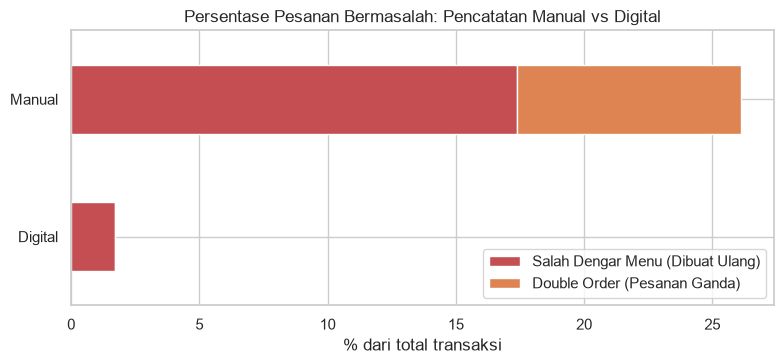

In [39]:
# Visualisasikan perbandingan persentase pesanan bermasalah (Manual vs Digital)
fig, ax = plt.subplots(figsize=(8, 3.8))
kolom_error = ["Salah Dengar Menu (Dibuat Ulang)", "Double Order (Pesanan Ganda)"]
persen_masalah[kolom_error].plot(kind="barh", stacked=True, ax=ax, color=["#C44E52", "#DD8452"])

ax.set(title="Persentase Pesanan Bermasalah: Pencatatan Manual vs Digital", xlabel="% dari total transaksi", ylabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [40]:
# Bandingkan persentase pesanan bermasalah saat kondisi Normal vs Ramai (Peak Hour)
persen_situasi = (
    df.groupby(["Jenis_Pencatatan", "Situasi_Kedai"])["Is_Pesanan_Bermasalah"]
      .mean().mul(100).round(1).unstack()
)
persen_situasi

Situasi_Kedai,Normal,Ramai (Peak Hour)
Jenis_Pencatatan,,
Digital,1.6,1.7
Manual,10.9,36.5


In [41]:
# Hitung total kasus dan nilai transaksi yang terdampak kesalahan pesanan
kasus_bermasalah = df[df["Is_Pesanan_Bermasalah"]]
print(f"Total pesanan bermasalah  : {len(kasus_bermasalah)} transaksi")
print(f"Total nilai terdampak     : Rp{kasus_bermasalah['Total_Bayar_Kasir'].sum():,}")

Total pesanan bermasalah  : 152 transaksi
Total nilai terdampak     : Rp5,285,400


**Temuan Pertanyaan 1:**
- Pencatatan **manual** memiliki **±26,1% pesanan bermasalah** (17,4% salah dengar + 8,7% *double order*), sedangkan pencatatan **digital** hanya **±1,7%** dan **0% *double order***.
- Saat kedai **ramai (*peak hour*)**, tingkat kesalahan pencatatan manual melonjak dari **10,9% menjadi 36,5%**, sementara pencatatan digital tetap stabil di **1,7%**.
- Total ada **152 pesanan bermasalah** dengan nilai transaksi terdampak **±Rp5,29 juta**. Ini mendukung pentingnya fitur pemesanan/ringkasan pilihan menu digital di platform untuk mengurangi kesalahan saat kedai ramai.

### Pertanyaan 2: Kontribusi Member & Pola Loyalitas
Seberapa besar kontribusi member terhadap omzet, dan apakah level member berhubungan dengan frekuensi kunjungan serta nilai belanja?

In [42]:
# Bandingkan jumlah transaksi, omzet, dan rata-rata nota antara Member vs Non-Member
ringkasan_status = df.assign(Status=np.where(df["Is_Member"], "Member", "Non-Member")).groupby("Status").agg(
    transaksi=("No_Nota_Transaksi", "count"),
    omzet=("Total_Bayar_Kasir", "sum"),
    rata_nota=("Total_Bayar_Kasir", "mean")
)
ringkasan_status["porsi_omzet_%"] = (ringkasan_status["omzet"] / ringkasan_status["omzet"].sum() * 100).round(1)
ringkasan_status.round(0)

,transaksi,omzet,rata_nota,porsi_omzet_%
Status,,,,
Member,1746,59915400,34316.0,68.0
Non-Member,754,27569000,36564.0,32.0


In [43]:
# Rinci performa per Level_Member (transaksi, omzet, rata-rata kunjungan, saldo poin, dan rata-rata nota)
ringkasan_level = df.groupby("Level_Member", observed=True).agg(
    transaksi=("No_Nota_Transaksi", "count"),
    omzet=("Total_Bayar_Kasir", "sum"),
    rata_kunjungan=("Kunjungan_Bulan_Ini", "mean"),
    rata_poin=("Saldo_Poin", "mean"),
    rata_nota=("Total_Bayar_Kasir", "mean")
)
ringkasan_level["porsi_omzet_%"] = (ringkasan_level["omzet"] / ringkasan_level["omzet"].sum() * 100).round(1)
ringkasan_level.round(1)

,transaksi,omzet,rata_kunjungan,rata_poin,rata_nota,porsi_omzet_%
Level_Member,,,,,,
Non-Member,754,27569000,2.0,0.0,36563.7,31.5
Bronze,875,31793000,3.9,48.7,36334.9,36.3
Silver,585,19324900,7.0,124.1,33034.0,22.1
Gold,286,8797500,13.1,317.2,30760.5,10.1


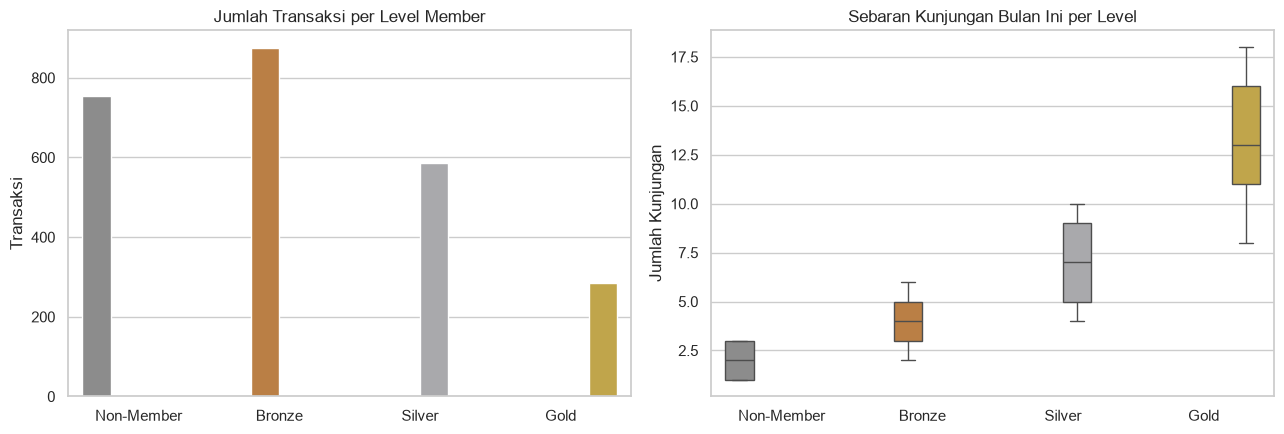

In [44]:
# Visualisasikan sebaran transaksi dan frekuensi kunjungan per level member
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

warna_level = ["#8C8C8C", "#CD7F32", "#A8A9AD", "#D4AF37"]
sns.barplot(x=ringkasan_level.index, y=ringkasan_level["transaksi"], ax=axes[0],
            palette=warna_level, hue=ringkasan_level.index, legend=False)
axes[0].set(title="Jumlah Transaksi per Level Member", xlabel="", ylabel="Transaksi")

data_kunjungan = df.dropna(subset=["Kunjungan_Bulan_Ini"]).astype({"Kunjungan_Bulan_Ini": float})
sns.boxplot(data=data_kunjungan, x="Level_Member", y="Kunjungan_Bulan_Ini", ax=axes[1],
            palette=warna_level, hue="Level_Member", legend=False)
axes[1].set(title="Sebaran Kunjungan Bulan Ini per Level", xlabel="", ylabel="Jumlah Kunjungan")

plt.tight_layout()
plt.show()

In [45]:
# Cek korelasi Spearman antara kunjungan, poin, dan nilai transaksi khusus pelanggan member
kolom_korelasi = ["Kunjungan_Bulan_Ini", "Saldo_Poin", "Total_Bayar_Kasir"]
df.loc[df["Is_Member"], kolom_korelasi].astype(float).corr(method="spearman").round(2)

,Kunjungan_Bulan_Ini,Saldo_Poin,Total_Bayar_Kasir
Kunjungan_Bulan_Ini,1.00,0.72,-0.07
Saldo_Poin,0.72,1.00,-0.03
Total_Bayar_Kasir,-0.07,-0.03,1.00


**Temuan Pertanyaan 2:**
- Member menyumbang **±68,5% omzet** (1.746 transaksi), dengan sebaran level berbentuk piramida: **Bronze (875)** > **Silver (585)** > **Gold (286)**.
- Level member berkaitan erat dengan **frekuensi kunjungan**: rata-rata kunjungan bulan ini naik dari **3,9× (Bronze)** → **7,0× (Silver)** → **13,1× (Gold)**, dan berkorelasi kuat dengan saldo poin (Spearman **0,72**).
- Menariknya, frekuensi kunjungan **tidak berkorelasi** dengan nilai belanja per nota (Spearman **-0,07**). Artinya pelanggan setia datang lebih sering, bukan belanja lebih mahal sekali datang—sehingga program poin berbasis kunjungan dan paket *bundling* cocok diterapkan.

### Pertanyaan 3: Menu Terlaris & Jam Operasional Paling Ramai
Menu apa yang paling banyak terjual dan menyumbang omzet tertinggi, serta pada jam berapa kedai paling sibuk?

In [46]:
# Hitung 10 menu terlaris berdasarkan total porsi/cup terjual dan omzetnya
top_menu = (
    df.groupby("Nama_Menu_Terjual")
      .agg(qty=("Qty_Cup_Porsi", "sum"), omzet=("Total_Bayar_Kasir", "sum"), transaksi=("No_Nota_Transaksi", "count"))
      .sort_values("qty", ascending=False)
)
top_menu.head(10)

,qty,omzet,transaksi
Nama_Menu_Terjual,,,
Signature Cokelat Kental Original,68,1201500,36
Croffle Choco Almond (Isi 2),62,1223000,36
Hot Signature Cokelat Kental,59,1045800,34
Churros Spanyol Saus Cokelat Kental,59,980900,29
Mini Pancake Cokelat Meses,59,860250,29
Waffle Ice Cream Strawberry Choco,59,1260600,34
Kids Bento Nasi Sosis & Nugget,58,1128000,30
Cokelat Kental Coconut Paradiso,56,1140300,29
Nasi Goreng Kampung Cabe Ijo,56,1258100,24


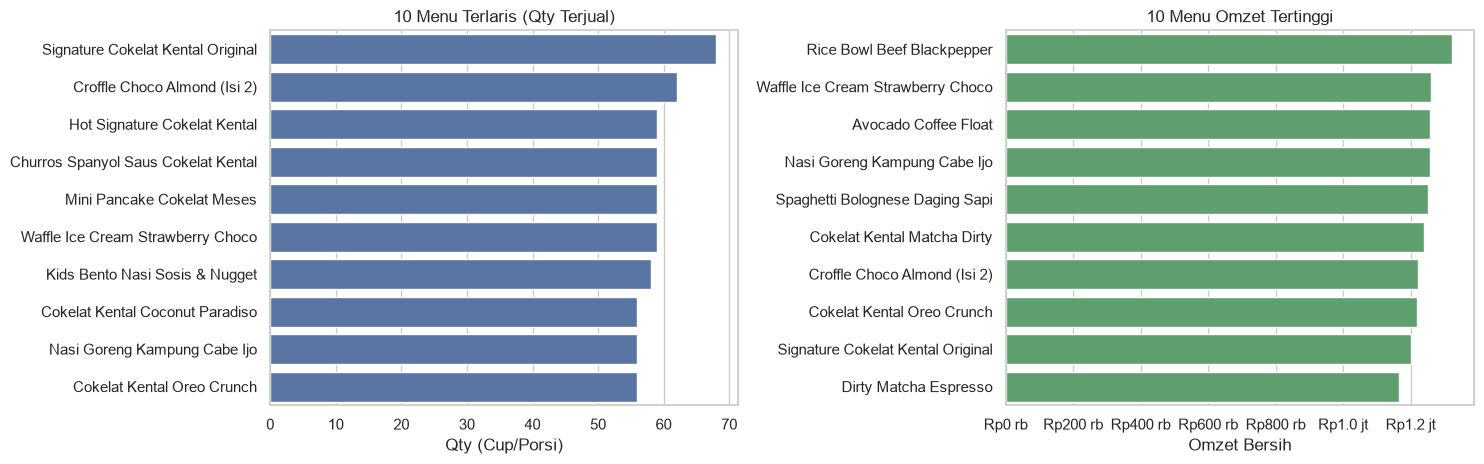

In [47]:
# Visualisasikan 10 menu terlaris (berdasarkan qty) dan 10 menu beromzet tertinggi
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

top_qty = top_menu.nlargest(10, "qty").reset_index()
sns.barplot(data=top_qty, y="Nama_Menu_Terjual", x="qty", ax=axes[0], color="#4C72B0")
axes[0].set(title="10 Menu Terlaris (Qty Terjual)", xlabel="Qty (Cup/Porsi)", ylabel="")

top_omzet = top_menu.nlargest(10, "omzet").reset_index()
sns.barplot(data=top_omzet, y="Nama_Menu_Terjual", x="omzet", ax=axes[1], color="#55A868")
axes[1].set(title="10 Menu Omzet Tertinggi", xlabel="Omzet Bersih", ylabel="")
format_rupiah(axes[1])

plt.tight_layout()
plt.show()

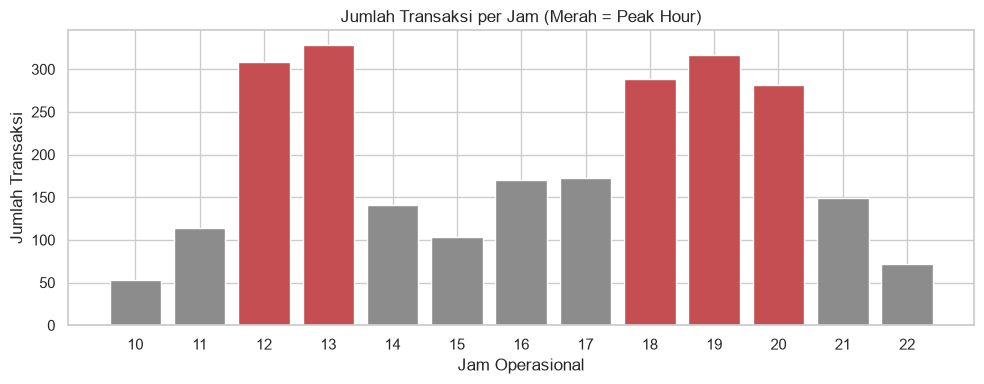

In [48]:
# Hitung jumlah transaksi per jam dan tampilkan grafik jam ramai
per_jam = df.groupby("Jam")["No_Nota_Transaksi"].count()

fig, ax = plt.subplots(figsize=(10, 4))
warna_jam = ["#C44E52" if j in jam_ramai else "#8C8C8C" for j in per_jam.index]
ax.bar(per_jam.index, per_jam.values, color=warna_jam)
ax.set(title="Jumlah Transaksi per Jam (Merah = Peak Hour)", xlabel="Jam Operasional", ylabel="Jumlah Transaksi", xticks=per_jam.index)
plt.tight_layout()
plt.show()

In [49]:
# Bandingkan rata-rata durasi penyajian antara kondisi Normal vs Ramai
df.dropna(subset=["Durasi_Penyajian_Menit"]).groupby("Situasi_Kedai")["Durasi_Penyajian_Menit"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Situasi_Kedai,,,,,,,,
Normal,923.0,7.9,3.3,4.0,6.0,8.0,10.0,26.0
Ramai (Peak Hour),1451.0,8.8,4.4,4.0,6.0,8.0,10.0,26.0


**Temuan Pertanyaan 3:**
- Menu terlaris secara kuantitas adalah **Signature Cokelat Kental Original (68 porsi)**, diikuti *Croffle Choco Almond* (62 porsi) serta *Waffle Ice Cream Strawberry Choco*, *Churros Spanyol*, *Mini Pancake Cokelat Meses*, dan *Hot Signature Cokelat Kental* (masing-masing 59 porsi). Penjualan tersebar merata di berbagai menu.
- Terdapat **dua gelombang jam sibuk (*peak hour*)**: jam makan siang (**12.00–13.00**) dan malam (**18.00–20.00**), yang mencakup sekitar **61% dari seluruh transaksi**.
- Median durasi penyajian tetap 8 menit, tetapi saat ramai rata-ratanya meningkat (**8,8 menit** vs **7,9 menit** saat normal). Persiapan bahan sebelum jam 12 dan jam 18 dapat membantu menjaga kecepatan saji.

## 5. Kesimpulan & Rekomendasi

> *Seluruh kesimpulan didasarkan pada data dummy dan bersifat ilustratif; validasi ulang diperlukan saat data transaksi nyata dari aplikasi sudah terkumpul.*

1. **Digitalisasi pemesanan menekan kesalahan:** Pencatatan manual mencatat ±26,1% kesalahan pesanan (naik hingga ±36,5% saat ramai), dibanding ±1,7% pada pencatatan digital. Fitur pemesanan web/chatbot dan *ringkasan pilihan menu* untuk kasir sangat relevan untuk diterapkan.
2. **Loyalitas member didorong oleh frekuensi kunjungan:** Member level Gold datang ±3× lebih sering daripada Bronze (13,1 vs 3,9 kunjungan/bulan), sementara nilai belanja per nota relatif sama. Sistem poin sebaiknya menghargai frekuensi kunjungan, dan nilai transaksi dapat didorong lewat paket *bundling*.
3. **Fokus persiapan di jam puncak & menu unggulan:** Sekitar 61% transaksi terjadi pada pukul 12–13 dan 18–20, dengan dominasi menu berbasis cokelat dan *dessert*. Data ini dapat menjadi indikator awal pada dasbor pemilik.

## 6. Output Data & Cara Penggunaan

Dataset bersih disimpan ke `data/transaksi_member_clean.csv` agar dapat langsung dipakai tim Full-Stack (sebagai *seed data* dummy panel admin & poin) maupun tim Data Science (untuk pengembangan dasbor pemilik).

In [ ]:
# Path export data clean
PATH_CLEAN = "data/processed/transaksi_member_clean.csv"

In [51]:
# Simpan dataframe bersih ke CSV (tanpa kolom index pandas)
df.to_csv(PATH_CLEAN, index=False, date_format="%Y-%m-%d %H:%M:%S")
print(f"Dataset bersih tersimpan di: {PATH_CLEAN} ({len(df):,} baris × {df.shape[1]} kolom)")

Dataset bersih tersimpan di: data/transaksi_member_clean.csv (2,500 baris × 26 kolom)


In [52]:
# Contoh cara memuat ulang dataset bersih untuk tim lain
cek_baca = pd.read_csv(PATH_CLEAN, parse_dates=["Tgl_Order", "Waktu_Transaksi"])
cek_baca.head(3)

,No_Nota_Transaksi,Tgl_Order,Waktu_Order,Situasi_Kedai,ID_Member_Pelanggan,Level_Member,Kategori_Pelanggan,Kunjungan_Bulan_Ini,Saldo_Poin,Sumber_Order,Cara_Catat_Kasir,Kode_Menu_Pesanan,Nama_Menu_Terjual,Qty_Cup_Porsi,Harga_Satuan,Potongan_Diskon_Member,Total_Bayar_Kasir,Catatan_Kesesuaian_Order,Durasi_Penyajian_Menit,Waktu_Transaksi,Is_Member,Jam,Bulan,Subtotal_Kotor,Jenis_Pencatatan,Is_Pesanan_Bermasalah
0,TS-2026-0001,2026-10-02,21:08,Normal,NON-MBR,Non-Member,Mahasiswa,2.0,0.0,Chatbot WhatsApp/Web,Otomatis Digital (Web/Chatbot),MN095,Soto Betawi Creamy Susu + Nasi,1,28000,0,28000,Sesuai Pesanan,8.0,2026-10-02 21:08:00,False,21,2026-10,28000,Digital,False
1,TS-2026-0002,2026-07-26,13:21,Ramai (Peak Hour),MBR-1350,Bronze,Ibu Rumah Tangga,2.0,34.0,Website Membership & Order,Otomatis Digital (Web/Chatbot),MN057,Strawberry Milkshake Ceria,1,16000,0,16000,Sesuai Pesanan,11.0,2026-07-26 13:21:00,True,13,2026-07,16000,Digital,False
2,TS-2026-0003,2026-06-17,12:00,Ramai (Peak Hour),NON-MBR,Non-Member,Pekerja,3.0,0.0,Website Membership & Order,Otomatis Digital (Web/Chatbot),MN097,Tahu Cabai Garam Crispy,1,15000,0,15000,Sesuai Pesanan,5.0,2026-06-17 12:00:00,False,12,2026-06,15000,Digital,False


### Keterbatasan Data
- **Data dummy:** Pola dan angka dibuat oleh tim untuk simulasi, bukan data asli Tujuan Semata.
- **Level member per ID:** Pada data dummy ini, satu `ID_Member_Pelanggan` bisa memiliki label level yang berbeda antartransaksi, sehingga level dianalisis sebagai *level saat transaksi*.
- **Missing value tersisa:** Sebagian `Kunjungan_Bulan_Ini` (165 baris), `Durasi_Penyajian_Menit` (126 baris), dan `Saldo_Poin` member (73 baris) dibiarkan kosong agar tidak menimbulkan bias imputasi.